# Lecture · Evaluation, deep learning and research practice

This notebook follows the slides. All images are **NIfTI (`.nii` / `.nii.gz`)** files.

| Part | Topic | Main tools |
|---|---|---|
| 0 | Setup and data | `nibabel`, `numpy` |
| 1.1 | Physical units: volume, area, surface | `nibabel`, `skimage.measure` |
| 1.2 | Segmentation metrics: Dice, IoU, Hausdorff, HD95 | `scipy.ndimage` |
| 1.3 | Classification metrics: confusion matrix, ROC, AUC | `scikit-learn` |
| 1.4 | Radiomics | `numpy`, `pyradiomics` (optional) |
| 2.1 | Tensors and channel-first layout | `torch` |
| 2.2 | Datasets, DataLoaders and patient-level splits | `torch`, `scikit-learn` |
| 2.3 | Augmentation | `monai` |
| 2.4 | Worked example: 2D U-Net segmentation | `monai` |
| 3.1 | Reproducibility: seeds, versions, Git | |
| 3.2 | Project layout | `pathlib` |
| 3.3 | Large 3D data: memory, lazy loading, patches | `nibabel`, `numpy` |
| 4 | Exercises | |

**Data.** The notebook generates its own synthetic data, so it runs anywhere without downloads:
a 3D abdominal CT phantom with a spleen label, a simulated segmentation to evaluate, simulated classifier scores, and a small 2D lesion dataset for the U-Net.
If you completed Session 5, you can evaluate your own classical segmentation instead (see Part 0).

**Requirements.** Part 1 and Part 3 need only `numpy`, `scipy`, `scikit-image`, `scikit-learn`, `pandas`, `matplotlib` and `nibabel`. Part 2 also needs `torch` and `monai`. In Google Colab, PyTorch is pre-installed; run the `pip` cell below.

## 0 · Setup and data

In [1]:
# Colab / fresh environment: uncomment and run once
# !pip install nibabel monai scikit-image scikit-learn
# Optional, for Part 1.4 (installation can fail on very new Python versions):
# !pip install pyradiomics

In [2]:
import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
from scipy import ndimage, stats
from skimage import measure
from sklearn import metrics
from sklearn.model_selection import GroupShuffleSplit, train_test_split

plt.rcParams["figure.dpi"] = 100
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)


def set_seed(seed=42):
    # Fix every random number generator we use (explained in Part 3.1).
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except ImportError:
        pass


SEED = 42
set_seed(SEED)
print("nibabel", nib.__version__, "| numpy", np.__version__)

nibabel 5.2.1 | numpy 1.26.4


### A 3D CT phantom, its ground-truth label and a simulated segmentation
Values are in Hounsfield units. Slices are 2.5 mm thick and pixels 0.8 mm, so voxels are **anisotropic**, which matters for every metric in millimetres.

The simulated "prediction" is the ground truth shifted by 2 voxels and grown by 1 voxel: a decent but imperfect segmentation. A second version adds a small false-positive blob far from the spleen.

In [3]:
def make_phantom(shape=(192, 192, 64), spacing=(0.8, 0.8, 2.5), seed=0):
    rng = np.random.default_rng(seed)
    x, y, z = np.meshgrid(*[np.arange(n) * s for n, s in zip(shape, spacing)], indexing="ij")
    cx, cy, cz = [n * s / 2 for n, s in zip(shape, spacing)]

    def ellipsoid(centre, radii):
        return sum(((c - c0) / r) ** 2 for c, c0, r in zip((x, y, z), centre, radii)) <= 1

    ct = np.full(shape, -1000.0)
    ct[ellipsoid((cx, cy, cz), (70, 55, 1e4))] = -100                 # fat
    ct[ellipsoid((cx, cy, cz), (64, 49, 1e4))] = 40                   # soft tissue
    ct[ellipsoid((cx + 25, cy - 5, cz), (30, 28, 60))] = 60           # liver (patient's right)
    spleen = ellipsoid((cx - 38, cy + 5, cz), (14, 20, 40))           # spleen (patient's left)
    ct[spleen] = 110
    ct[ellipsoid((cx, cy - 35, cz), (12, 12, 1e4))] = 700             # spine
    ct = ndimage.gaussian_filter(ct, sigma=(1.0, 1.0, 0.4)) + rng.normal(0, 20, shape)

    fp_blob = ellipsoid((cx - 10, cy + 40, cz + 20), (3, 3, 3))       # small blob, far from the spleen
    return ct.astype(np.int16), spleen.astype(np.uint8), fp_blob, np.diag([*spacing, 1.0])


ct_arr, truth_arr, fp_blob, affine = make_phantom()
pred_arr = ndimage.binary_dilation(np.roll(truth_arr, 2, axis=0)).astype(np.uint8)
pred_fp_arr = (pred_arr.astype(bool) | fp_blob).astype(np.uint8)

nib.save(nib.Nifti1Image(ct_arr, affine), DATA_DIR / "ct.nii.gz")
nib.save(nib.Nifti1Image(truth_arr, affine), DATA_DIR / "label.nii.gz")
nib.save(nib.Nifti1Image(pred_arr, affine), DATA_DIR / "pred.nii.gz")
nib.save(nib.Nifti1Image(pred_fp_arr, affine), DATA_DIR / "pred_fp.nii.gz")
print("Saved ct, label, pred and pred_fp NIfTI files to", DATA_DIR)

Saved ct, label, pred and pred_fp NIfTI files to data


In [4]:
# Use these paths from here on.
CT_PATH = DATA_DIR / "ct.nii.gz"
LABEL_PATH = DATA_DIR / "label.nii.gz"
PRED_PATH = DATA_DIR / "pred.nii.gz"

# To evaluate your Session 5 classical segmentation instead (same grid as its label):
# LABEL_PATH = Path("data/label_iso.nii.gz")
# PRED_PATH = Path("data/spleen_seg_classical.nii.gz")

A small viewer: an axial slice with the ground truth (green) and prediction (orange) contours.

Shape (192, 192, 64) | spacing (mm) (0.800000011920929, 0.800000011920929, 2.5)


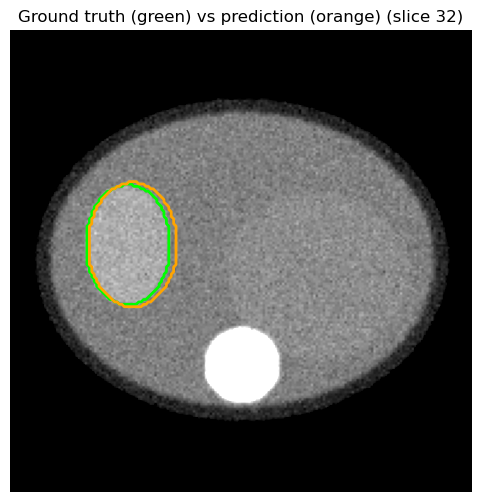

In [5]:
def show_contours(img, masks, colors, z=None, title="", window=(-160, 240)):
    if z is None:
        z = int(ndimage.center_of_mass(masks[0])[2])
    plt.figure(figsize=(6, 6))
    plt.imshow(np.rot90(img[:, :, z]), cmap="gray", vmin=window[0], vmax=window[1])
    for m, c in zip(masks, colors):
        if m[:, :, z].any():
            plt.contour(np.rot90(m[:, :, z]), levels=[0.5], colors=c, linewidths=2)
    plt.title(f"{title} (slice {z})")
    plt.axis("off")
    plt.show()


ct_img = nib.load(CT_PATH)
ct = ct_img.get_fdata(dtype=np.float32)
truth = np.asarray(nib.load(LABEL_PATH).dataobj) > 0
pred = np.asarray(nib.load(PRED_PATH).dataobj) > 0
spacing = tuple(float(s) for s in ct_img.header.get_zooms()[:3])
print("Shape", ct.shape, "| spacing (mm)", spacing)

show_contours(ct, [truth, pred], ["lime", "orange"], title="Ground truth (green) vs prediction (orange)")

---
# Part 1 · Measure and evaluate
## 1.1 · Physical units: volume, area and surface

**volume (mm³) = voxel count × sx × sy × sz**, and 1 mL = 1000 mm³. The spacing comes from the header.

In [6]:
def volume_ml(mask, spacing):
    return mask.sum() * np.prod(spacing) / 1000


def slice_areas_mm2(mask, spacing):
    return mask.sum(axis=(0, 1)) * spacing[0] * spacing[1]       # one value per axial slice


def surface_area_mm2(mask, spacing):
    verts, faces, _, _ = measure.marching_cubes(mask.astype(np.uint8), 0.5, spacing=spacing)
    return measure.mesh_surface_area(verts, faces)


print(f"Voxel count:      {truth.sum()} voxels (meaningless on its own)")
print(f"Volume:           {volume_ml(truth, spacing):.1f} mL")
print(f"Largest slice:    {slice_areas_mm2(truth, spacing).max():.0f} mm²")
print(f"Surface area:     {surface_area_mm2(truth, spacing):.0f} mm²")

# Pitfall: forgetting the spacing (treating voxels as 1 mm cubes)
print(f"\nVolume if spacing is ignored: {truth.sum() / 1000:.1f} 'mL'  <- wrong by a factor {np.prod(spacing):.1f}")

Voxel count:      29254 voxels (meaningless on its own)
Volume:           46.8 mL
Largest slice:    874 mm²
Surface area:     7825 mm²

Volume if spacing is ignored: 29.3 'mL'  <- wrong by a factor 1.6


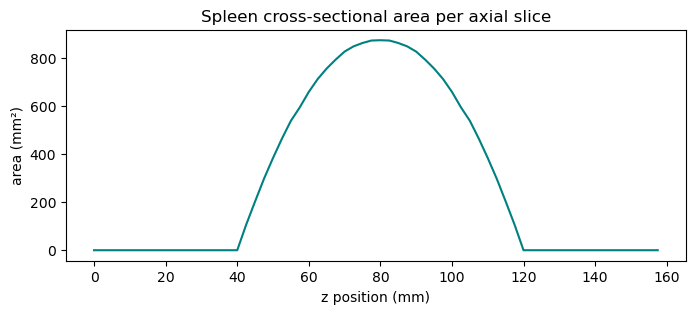

Sum of areas x thickness: 46.8 mL


In [7]:
areas = slice_areas_mm2(truth, spacing)
z_mm = np.arange(len(areas)) * spacing[2]
plt.figure(figsize=(8, 3))
plt.plot(z_mm, areas, color="teal")
plt.xlabel("z position (mm)")
plt.ylabel("area (mm²)")
plt.title("Spleen cross-sectional area per axial slice")
plt.show()

# Sanity check: summing area x slice thickness gives the volume again
print(f"Sum of areas x thickness: {areas.sum() * spacing[2] / 1000:.1f} mL")

## 1.2 · Segmentation metrics
| Metric | Measures | Best |
|---|---|---|
| Dice | 2\|A∩B\| / (\|A\| + \|B\|) | 1 |
| IoU (Jaccard) | \|A∩B\| / \|A∪B\| | 1 |
| Hausdorff (HD) | worst boundary distance, mm | 0 |
| HD95 | 95th-percentile boundary distance, mm | 0 |
| ASSD | average symmetric surface distance, mm | 0 |

In [8]:
def dice(a, b, empty_value=1.0):
    a, b = a.astype(bool), b.astype(bool)
    denom = a.sum() + b.sum()
    return empty_value if denom == 0 else 2 * (a & b).sum() / denom


def iou(a, b, empty_value=1.0):
    a, b = a.astype(bool), b.astype(bool)
    union = (a | b).sum()
    return empty_value if union == 0 else (a & b).sum() / union


def surface(m):
    return m & ~ndimage.binary_erosion(m)


def surface_distances(a, b, spacing):
    # Distance (mm) from every boundary voxel of a to the nearest boundary voxel of b.
    dist_to_b = ndimage.distance_transform_edt(~surface(b), sampling=spacing)
    return dist_to_b[surface(a)]


def boundary_metrics(a, b, spacing):
    a, b = a.astype(bool), b.astype(bool)
    d_ab, d_ba = surface_distances(a, b, spacing), surface_distances(b, a, spacing)
    return {
        "HD (mm)": max(d_ab.max(), d_ba.max()),
        "HD95 (mm)": max(np.percentile(d_ab, 95), np.percentile(d_ba, 95)),
        "ASSD (mm)": (d_ab.sum() + d_ba.sum()) / (len(d_ab) + len(d_ba)),
    }


# Check against the worked example on the slides: |A| = 100, |B| = 80, overlap 60
A = np.zeros(200, bool); A[:100] = True
B = np.zeros(200, bool); B[40:120] = True
print(f"Slide example: Dice = {dice(A, B):.2f}, IoU = {iou(A, B):.2f}")

Slide example: Dice = 0.67, IoU = 0.50


In [9]:
pred_fp = np.asarray(nib.load(DATA_DIR / "pred_fp.nii.gz").dataobj) > 0

rows = {}
for name, p in [("Prediction", pred), ("Prediction + false-positive blob", pred_fp)]:
    rows[name] = {"Dice": dice(truth, p), "IoU": iou(truth, p),
                  **boundary_metrics(truth, p, spacing),
                  "Volume error (mL)": volume_ml(p, spacing) - volume_ml(truth, spacing)}
results = pd.DataFrame(rows).T.round(3)
results

,Dice,IoU,HD (mm),HD95 (mm),ASSD (mm),Volume error (mL)
Prediction,0.903,0.823,2.968,2.530,1.327,6.592
Prediction + false-positive blob,0.902,0.821,31.558,2.625,1.535,6.714


The small blob barely changes Dice, IoU or HD95, but the Hausdorff distance jumps to the blob's distance from the spleen. HD95 ignores the worst 5% of boundary points, so it is robust to tiny outliers; a larger blob (try a 5 mm radius in `make_phantom`) would push HD95 up as well. Overlap metrics alone would never reveal the blob: that is why we report **one overlap and one boundary metric**.

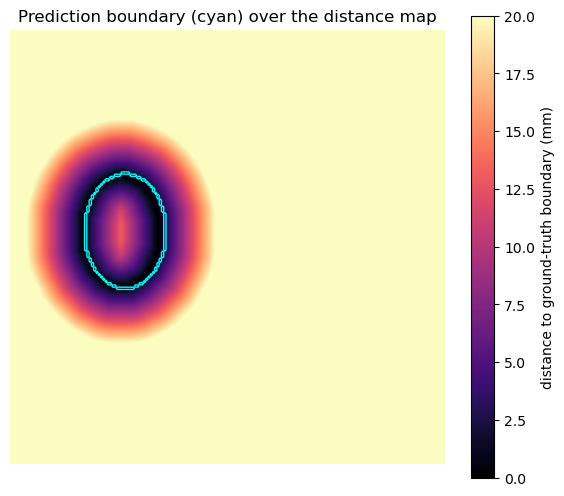

In [10]:
# What the distance transform looks like: distance (mm) to the ground-truth boundary
z = int(ndimage.center_of_mass(truth)[2])
dist = ndimage.distance_transform_edt(~surface(truth), sampling=spacing)

plt.figure(figsize=(7, 6))
plt.imshow(np.rot90(dist[:, :, z]), cmap="magma", vmax=20)           # clip at 20 mm to see detail
plt.colorbar(label="distance to ground-truth boundary (mm)")
plt.contour(np.rot90(surface(pred)[:, :, z]), levels=[0.5], colors="cyan", linewidths=1)
plt.title("Prediction boundary (cyan) over the distance map")
plt.axis("off")
plt.show()

In [11]:
# Why spacing matters for boundary metrics: the same masks, spacing ignored
right = boundary_metrics(truth, pred_fp, spacing)
wrong = boundary_metrics(truth, pred_fp, (1, 1, 1))
print(f"HD with spacing:   {right['HD (mm)']:.1f} mm")
print(f"HD ignoring it:    {wrong['HD (mm)']:.1f} 'mm' (actually a distance in voxels, mixing 0.8 mm and 2.5 mm steps)")

HD with spacing:   31.6 mm
HD ignoring it:    38.0 'mm' (actually a distance in voxels, mixing 0.8 mm and 2.5 mm steps)


In [12]:
# Dice depends on object size: grow a large and a small sphere by one voxel
def sphere(r, n=80):
    g = np.indices((n, n, n)) - n // 2
    return (g ** 2).sum(0) <= r ** 2

for r in [20, 4]:
    s = sphere(r)
    grown = ndimage.binary_dilation(s)
    print(f"radius {r:2d} voxels: one-voxel error gives Dice = {dice(s, grown):.3f}")

radius 20 voxels: one-voxel error gives Dice = 0.939
radius  4 voxels: one-voxel error gives Dice = 0.734


> **Ready-made versions:** `monai.metrics.DiceMetric`, `HausdorffDistanceMetric(percentile=95)` and `SurfaceDistanceMetric` work on batched tensors; the `seg-metrics` and `surface-distance` packages work on NumPy arrays. Different packages define HD95 slightly differently, so state which one you used.

## 1.3 · Classification metrics
We simulate a classifier that outputs a probability of disease for 400 patients (prevalence 30%). Half the patients form a **validation** set (used to choose the threshold) and half a **test** set (used once, to report results).

In [13]:
rng = np.random.default_rng(SEED)
n = 400
label = (rng.random(n) < 0.3).astype(int)
logit = rng.normal(0, 1, n) + 1.8 * label - 0.9
df = pd.DataFrame({
    "patient_id": [f"P{i:03d}" for i in range(n)],
    "label": label,
    "prob": 1 / (1 + np.exp(-logit)),
})
df["split"] = np.where(rng.random(n) < 0.5, "val", "test")
df.head()

,patient_id,label,prob,split
0,P000,0,0.386900,test
1,P001,0,0.407137,test
2,P002,0,0.348935,test
3,P003,0,0.090071,val
4,P004,1,0.196218,val


In [14]:
def classification_report(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = metrics.confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "threshold": threshold,
        "sensitivity": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "PPV": tp / (tp + fp) if tp + fp else np.nan,
        "NPV": tn / (tn + fn) if tn + fn else np.nan,
        "accuracy": (tp + tn) / len(y_true),
        "AUC": metrics.roc_auc_score(y_true, y_prob),
    }


test = df[df.split == "test"]
pd.Series(classification_report(test.label.to_numpy(), test.prob.to_numpy())).round(3)

threshold      0.500
sensitivity    0.750
specificity    0.813
PPV            0.649
NPV            0.876
accuracy       0.793
AUC            0.865
dtype: float64

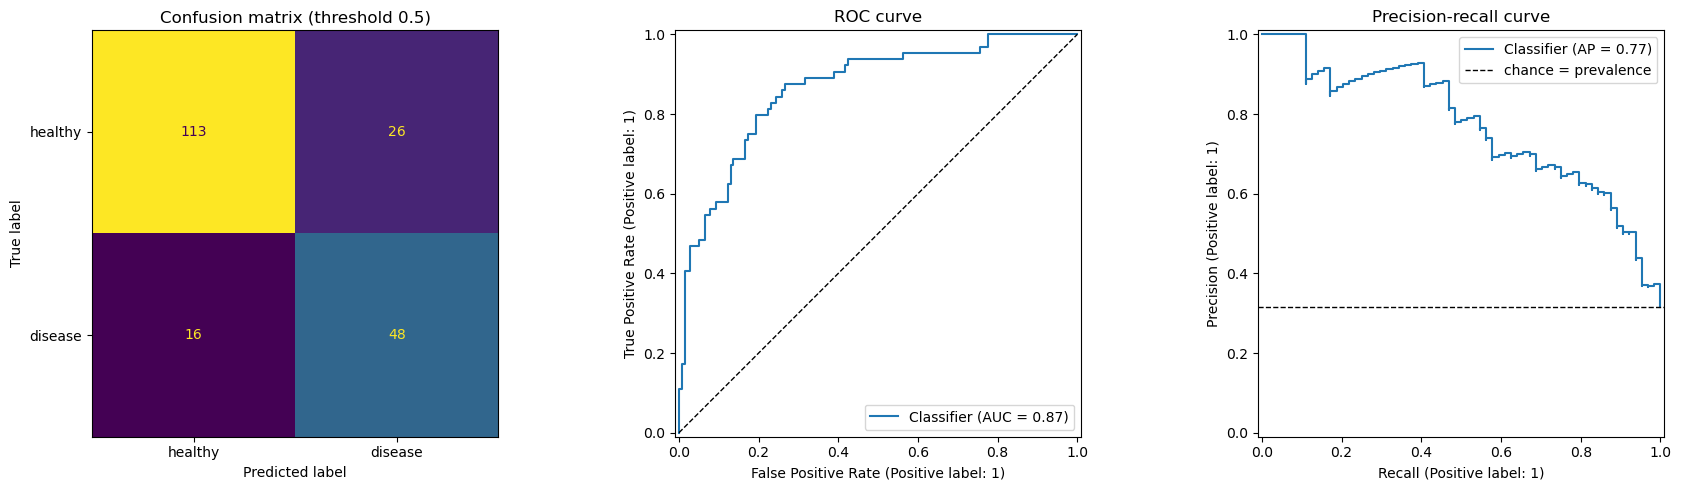

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
y_t, p_t = test.label.to_numpy(), test.prob.to_numpy()
metrics.ConfusionMatrixDisplay.from_predictions(y_t, (p_t >= 0.5).astype(int),
                                                display_labels=["healthy", "disease"], ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (threshold 0.5)")
metrics.RocCurveDisplay.from_predictions(y_t, p_t, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC curve")
metrics.PrecisionRecallDisplay.from_predictions(y_t, p_t, ax=axes[2])
axes[2].axhline(y_t.mean(), color="k", ls="--", lw=1, label="chance = prevalence")
axes[2].legend()
axes[2].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()

### Choosing the threshold on validation data, reporting on test data

In [16]:
val = df[df.split == "val"]
fpr, tpr, thresholds = metrics.roc_curve(val.label, val.prob)
youden_threshold = thresholds[np.argmax(tpr - fpr)]                 # maximises sens + spec - 1

# A screening tool might instead require sensitivity >= 0.90
screening_threshold = thresholds[np.argmax(tpr >= 0.90)]

summary = pd.DataFrame({
    "default 0.5": classification_report(y_t, p_t, 0.5),
    "Youden (from val)": classification_report(y_t, p_t, youden_threshold),
    "sens >= 0.90 (from val)": classification_report(y_t, p_t, screening_threshold),
}).T.round(3)
summary

,threshold,sensitivity,specificity,PPV,NPV,accuracy,AUC
default 0.5,0.500,0.750,0.813,0.649,0.876,0.793,0.865
Youden (from val),0.490,0.781,0.806,0.649,0.889,0.798,0.865
sens >= 0.90 (from val),0.334,0.938,0.525,0.476,0.948,0.655,0.865


In [17]:
# A 95% confidence interval for the AUC by bootstrapping patients
def bootstrap_auc(y_true, y_prob, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    aucs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) == 2:                         # need both classes
            aucs.append(metrics.roc_auc_score(y_true[idx], y_prob[idx]))
    return np.percentile(aucs, [2.5, 97.5])


lo, hi = bootstrap_auc(y_t, p_t)
print(f"Test AUC = {metrics.roc_auc_score(y_t, p_t):.3f} (95% CI {lo:.3f} to {hi:.3f})")

Test AUC = 0.865 (95% CI 0.809 to 0.916)


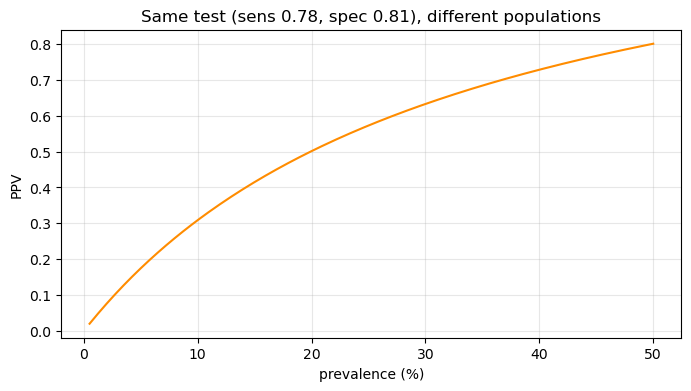

At 5% prevalence, 'always healthy' has accuracy 0.95 and sensitivity 0.00


In [18]:
# PPV depends on prevalence; sensitivity and specificity do not
rep = classification_report(y_t, p_t, youden_threshold)
sens, spec = rep["sensitivity"], rep["specificity"]
prev = np.linspace(0.005, 0.5, 200)
ppv = sens * prev / (sens * prev + (1 - spec) * (1 - prev))

plt.figure(figsize=(8, 4))
plt.plot(prev * 100, ppv, color="darkorange")
plt.xlabel("prevalence (%)")
plt.ylabel("PPV")
plt.title(f"Same test (sens {sens:.2f}, spec {spec:.2f}), different populations")
plt.grid(alpha=0.3)
plt.show()

# The accuracy trap
print(f"At 5% prevalence, 'always healthy' has accuracy 0.95 and sensitivity 0.00")

For a study, loop over patients to build a table (one row per patient), join it with the clinical labels, and do feature selection **inside** cross-validation.

---
# Part 2 · Bridge to deep learning
### A 2D lesion dataset with patient IDs
Each synthetic "patient" contributes 8 neighbouring slices of 64 × 64 pixels with a lesion whose size changes smoothly from slice to slice, like a real scan. This part needs only NumPy; the PyTorch cells follow.

images (480, 64, 64) float32 | masks (480, 64, 64) | patients 60


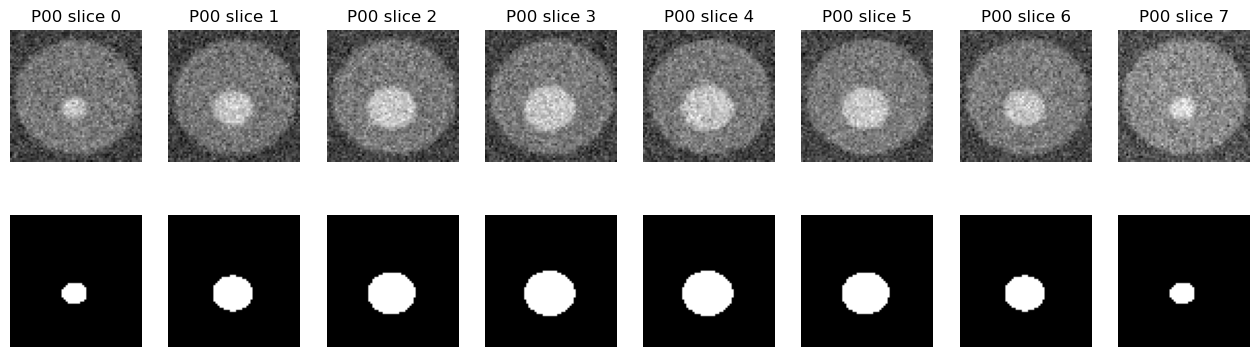

In [21]:
def make_patient(rng, n_slices=8, size=64):
    yy, xx = np.mgrid[:size, :size]
    body = ((yy - 32) / 28) ** 2 + ((xx - 32) / 30) ** 2 <= 1
    cy, cx = rng.uniform(22, 42, 2)
    r_max, aspect, contrast = rng.uniform(5, 12), rng.uniform(0.75, 1.3), rng.uniform(0.25, 0.6)
    images, masks = [], []
    for k in range(n_slices):
        t = (k - (n_slices - 1) / 2) / (n_slices / 2)
        r = r_max * np.sqrt(max(1 - t ** 2, 0.15))
        lesion = ((yy - cy) / r) ** 2 + ((xx - cx) / (r * aspect)) ** 2 <= 1
        img = ndimage.gaussian_filter(0.2 * body + contrast * lesion, 1.0) + rng.normal(0, 0.08, (size, size))
        images.append(img.astype(np.float32))
        masks.append(lesion.astype(np.uint8))
    return images, masks


rng = np.random.default_rng(SEED)
images, masks, patient_ids = [], [], []
for pid in range(60):
    im, m = make_patient(rng)
    images += im
    masks += m
    patient_ids += [f"P{pid:02d}"] * len(im)
images, masks, patient_ids = np.stack(images), np.stack(masks), np.array(patient_ids)
print("images", images.shape, images.dtype, "| masks", masks.shape, "| patients", len(np.unique(patient_ids)))

fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for k in range(8):
    axes[0, k].imshow(images[k], cmap="gray")
    axes[1, k].imshow(masks[k], cmap="gray")
    axes[0, k].set_title(f"{patient_ids[k]} slice {k}")
for ax in axes.ravel():
    ax.axis("off")
plt.show()

### Patient-level split (and what leakage looks like)

In [22]:
idx = np.arange(len(images))

# WRONG: split slices at random
tr_wrong, te_wrong = train_test_split(idx, test_size=0.2, random_state=SEED)
shared = set(patient_ids[tr_wrong]) & set(patient_ids[te_wrong])
print(f"Random slice split: {len(shared)} of {len(np.unique(patient_ids[te_wrong]))} test patients also appear in training")

# RIGHT: split patients (test 20%, then validation 20% of the rest)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
trval_idx, test_idx = next(gss.split(idx, groups=patient_ids))
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_rel, val_rel = next(gss_val.split(trval_idx, groups=patient_ids[trval_idx]))
train_idx, val_idx = trval_idx[tr_rel], trval_idx[val_rel]

sets = {name: set(patient_ids[i]) for name, i in [("train", train_idx), ("val", val_idx), ("test", test_idx)]}
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])
for name, i in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    print(f"{name:5s}: {len(i):3d} slices from {len(sets[name]):2d} patients")

train_x, train_y = images[train_idx], masks[train_idx]
val_x, val_y = images[val_idx], masks[val_idx]
test_x, test_y = images[test_idx], masks[test_idx]

Random slice split: 48 of 48 test patients also appear in training
train: 304 slices from 38 patients
val  :  80 slices from 10 patients
test :  96 slices from 12 patients


## 2.1 · Tensors and channel-first layout
**From here on the cells need PyTorch** (and later MONAI).

| Data | Layout |
|---|---|
| NIfTI volume from nibabel | (X, Y, Z) |
| One 2D image for a CNN | (C, H, W) |
| A batch of 2D images | (B, C, H, W) |
| A batch of 3D patches | (B, C, D, H, W) |

In [23]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device)

vol = ct_img.get_fdata(dtype=np.float32)       # (X, Y, Z) from Part 0
x = torch.from_numpy(vol)                      # shares memory with the NumPy array
x = x.permute(2, 0, 1)                         # (Z, X, Y): one item per axial slice
x = x.unsqueeze(1)                             # (Z, 1, X, Y) = (B, C, H, W)
print("batch of slices:", tuple(x.shape), x.dtype)

x = x.to(device)
mean_per_slice = x.mean(dim=(1, 2, 3))         # NumPy's axis= is dim= in PyTorch
back = mean_per_slice.cpu().numpy()            # back to NumPy (via the CPU)
print("mean HU of the first 5 slices:", back[:5].round(1))

# A 3D batch for a 3D network: add batch and channel axes
x3d = torch.from_numpy(vol)[None, None]        # (1, 1, X, Y, Z)
print("3D batch:", tuple(x3d.shape))

torch 2.6.0 | device: cpu
batch of slices: (64, 1, 192, 192) torch.float32
mean HU of the first 5 slices: [-467.7 -467.5 -467.8 -467.6 -467.5]
3D batch: (1, 1, 192, 192, 64)


## 2.2 · Dataset and DataLoader
A `Dataset` returns **one** sample; a `DataLoader` shuffles, batches and (optionally) loads in parallel.
We return a dictionary so the image and its mask travel together through every transform.

In [24]:
from torch.utils.data import Dataset, DataLoader


class SliceDataset(Dataset):
    def __init__(self, images, masks, transform=None):           # arrays of shape (N, H, W)
        self.images, self.masks, self.transform = images, masks, transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        sample = {"image": self.images[i][None].astype("float32"),   # add channel -> (1, H, W)
                  "label": self.masks[i][None].astype("float32")}
        return self.transform(sample) if self.transform else sample


loader = DataLoader(SliceDataset(train_x, train_y), batch_size=16, shuffle=True)
batch = next(iter(loader))
print("image batch:", tuple(batch["image"].shape), batch["image"].dtype)
print("label batch:", tuple(batch["label"].shape))

image batch: (16, 1, 64, 64) torch.float32
label batch: (16, 1, 64, 64)


## 2.3 · Augmentation with MONAI
* **Spatial** transforms (flip, rotate) are applied to the image **and** the label, with nearest-neighbour interpolation for the label.
* **Intensity** transforms (scaling, noise) are applied to the image only.
* Validation and test data are **never** augmented.

<python-environment>/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
<python-environment>/lib/python3.10/site-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
<python-environment>/lib/python3.10/site-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(


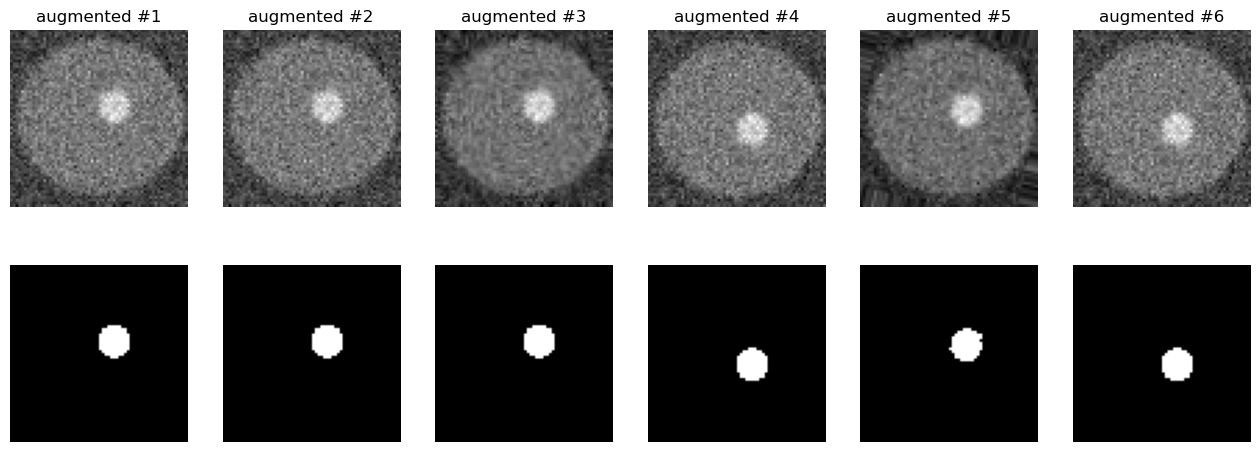

label values after rotation: tensor([0., 1.])


In [25]:
from monai.transforms import (Compose, EnsureTyped, RandFlipd, RandRotated,
                              RandScaleIntensityd, RandGaussianNoised)

keys = ["image", "label"]
train_tf = Compose([
    RandFlipd(keys, prob=0.5, spatial_axis=0),
    RandRotated(keys, range_x=0.26, prob=0.5, mode=("bilinear", "nearest")),   # +/- 15 degrees
    RandScaleIntensityd("image", factors=0.1, prob=0.5),
    RandGaussianNoised("image", prob=0.3, std=0.05),
    EnsureTyped(keys, track_meta=False),          # plain torch tensors
])
val_tf = EnsureTyped(keys, track_meta=False)
train_tf.set_random_state(seed=SEED)

# See what the network sees: one sample, augmented six times
ds_aug = SliceDataset(train_x, train_y, transform=train_tf)
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for k in range(6):
    s = ds_aug[3]
    axes[0, k].imshow(s["image"][0], cmap="gray")
    axes[1, k].imshow(s["label"][0], cmap="gray")
    axes[0, k].set_title(f"augmented #{k + 1}")
for ax in axes.ravel():
    ax.axis("off")
plt.show()
print("label values after rotation:", torch.unique(s["label"]))   # still only 0 and 1

> **TorchIO** offers the same idea with `tio.Subject(image=tio.ScalarImage(...), label=tio.LabelMap(...))` and transforms such as `tio.RandomFlip`, `tio.RandomAffine`, `tio.RandomNoise` and `tio.RandomBiasField`. It reads NIfTI paths directly.

## 2.4 · Worked example: 2D segmentation with a MONAI U-Net
Seeded DataLoaders make the shuffling order reproducible (see Part 3.1).

In [26]:
from monai.networks.nets import UNet
from monai.losses import DiceLoss
from monai.metrics import DiceMetric


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2 ** 32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


set_seed(SEED)
g = torch.Generator()
g.manual_seed(SEED)

train_loader = DataLoader(SliceDataset(train_x, train_y, transform=train_tf), batch_size=16, shuffle=True,
                          num_workers=0, worker_init_fn=seed_worker, generator=g)
val_loader = DataLoader(SliceDataset(val_x, val_y, transform=val_tf), batch_size=32, shuffle=False)

model = UNet(spatial_dims=2, in_channels=1, out_channels=1,
             channels=(16, 32, 64, 128), strides=(2, 2, 2), num_res_units=2).to(device)
loss_fn = DiceLoss(sigmoid=True)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
metric = DiceMetric(include_background=True, reduction="mean")
print(f"U-Net with {sum(p.numel() for p in model.parameters()):,} parameters")

U-Net with 401,288 parameters


In [27]:
EPOCHS = 15
history = {"train_loss": [], "val_dice": []}

for epoch in range(EPOCHS):
    model.train()
    losses = []
    for batch in train_loader:
        x, y = batch["image"].to(device), batch["label"].to(device)
        opt.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        opt.step()
        losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        for batch in val_loader:
            pred_b = (torch.sigmoid(model(batch["image"].to(device))) > 0.5).float()
            metric(y_pred=pred_b, y=batch["label"].to(device))
    history["train_loss"].append(np.mean(losses))
    history["val_dice"].append(metric.aggregate().item())
    metric.reset()
    print(f"epoch {epoch + 1:2d}: train loss {history['train_loss'][-1]:.3f}, val Dice {history['val_dice'][-1]:.3f}")

torch.save(model.state_dict(), DATA_DIR / "unet2d.pt")

epoch  1: train loss 0.903, val Dice 0.077
epoch  2: train loss 0.891, val Dice 0.077
epoch  3: train loss 0.887, val Dice 0.078
epoch  4: train loss 0.884, val Dice 0.078
epoch  5: train loss 0.882, val Dice 0.081
epoch  6: train loss 0.880, val Dice 0.087
epoch  7: train loss 0.878, val Dice 0.108
epoch  8: train loss 0.876, val Dice 0.169
epoch  9: train loss 0.873, val Dice 0.260
epoch 10: train loss 0.871, val Dice 0.378
epoch 11: train loss 0.869, val Dice 0.490
epoch 12: train loss 0.866, val Dice 0.565
epoch 13: train loss 0.863, val Dice 0.596
epoch 14: train loss 0.860, val Dice 0.593
epoch 15: train loss 0.856, val Dice 0.556


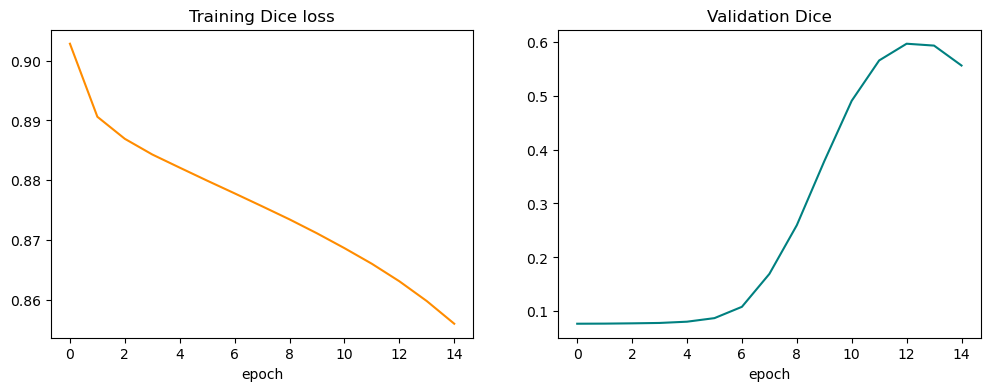

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], color="darkorange")
axes[0].set_title("Training Dice loss")
axes[1].plot(history["val_dice"], color="teal")
axes[1].set_title("Validation Dice")
for ax in axes:
    ax.set_xlabel("epoch")
plt.show()

### Final evaluation on the test patients
We predict every test slice, then compute a **per-patient** Dice by stacking each patient's slices into a small volume, using our own `dice` function from Part 1.2.

Test Dice per patient: mean 0.510, std 0.167, min 0.321


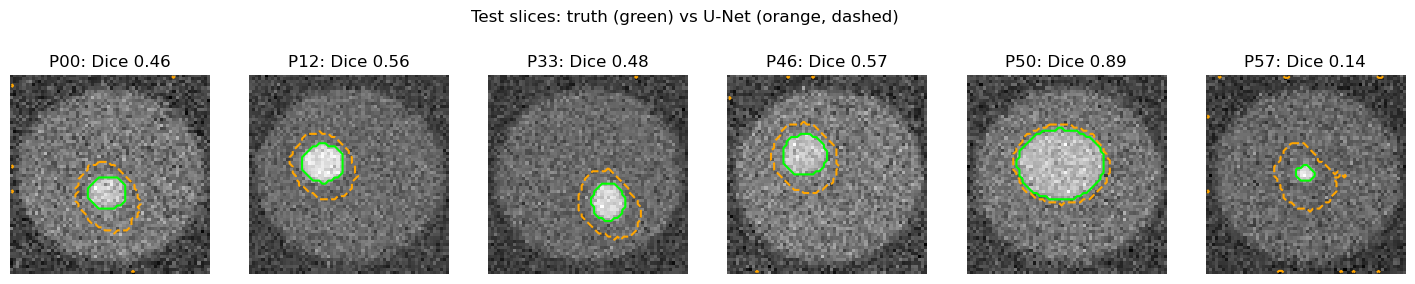

In [29]:
model.eval()
with torch.no_grad():
    logits = model(torch.from_numpy(test_x[:, None]).to(device))
    test_pred = (torch.sigmoid(logits) > 0.5).cpu().numpy()[:, 0]

per_patient = {pid: dice(test_y[patient_ids[test_idx] == pid], test_pred[patient_ids[test_idx] == pid])
               for pid in np.unique(patient_ids[test_idx])}
per_patient = pd.Series(per_patient, name="Dice")
print(f"Test Dice per patient: mean {per_patient.mean():.3f}, std {per_patient.std():.3f}, min {per_patient.min():.3f}")

fig, axes = plt.subplots(1, 6, figsize=(18, 3.4))
for ax, k in zip(axes, np.linspace(0, len(test_x) - 1, 6).astype(int)):
    ax.imshow(test_x[k], cmap="gray")
    ax.contour(test_y[k], levels=[0.5], colors="lime")
    ax.contour(test_pred[k], levels=[0.5], colors="orange", linestyles="--")
    ax.set_title(f"{patient_ids[test_idx][k]}: Dice {dice(test_y[k], test_pred[k]):.2f}")
    ax.axis("off")
plt.suptitle("Test slices: truth (green) vs U-Net (orange, dashed)")
plt.show()

---
# Part 3 · Good research practice
## 3.1 · Reproducibility: seeds, versions and Git
`set_seed` (Part 0) fixes Python, NumPy and PyTorch. For DataLoaders, also pass a seeded `torch.Generator` and a `worker_init_fn` (Part 2.4). MONAI has a shortcut: `monai.utils.set_determinism(seed)`.

Below we save a small **run record** next to the results: seed, package versions and the Git commit.

In [30]:
import platform
import subprocess
from importlib import metadata


def package_versions(names):
    out = {}
    for name in names:
        try:
            out[name] = metadata.version(name)
        except metadata.PackageNotFoundError:
            out[name] = "not installed"
    return out


def git_commit():
    try:
        return subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
    except (subprocess.CalledProcessError, FileNotFoundError):
        return "not a git repository"


versions = package_versions(["numpy", "scipy", "scikit-image", "scikit-learn", "pandas",
                             "nibabel", "torch", "monai", "pyradiomics"])
run_info = {"seed": SEED, "python": platform.python_version(), "git_commit": git_commit(), "packages": versions}
(DATA_DIR / "run_info.json").write_text(json.dumps(run_info, indent=2))
print(json.dumps(run_info, indent=2))

{
  "seed": 42,
  "python": "3.10.13",
  "git_commit": "not a git repository",
  "packages": {
    "numpy": "1.26.4",
    "scipy": "1.13.0",
    "scikit-image": "0.24.0",
    "scikit-learn": "1.6.1",
    "pandas": "2.2.3",
    "nibabel": "5.2.1",
    "torch": "2.6.0",
    "monai": "1.4.0",
    "pyradiomics": "not installed"
  }
}


In [31]:
# A hand-written requirements file with pinned versions (clearer than a full `pip freeze`)
req = "\n".join(f"{k}=={v}" for k, v in versions.items() if v != "not installed")
Path("requirements.txt").write_text(req + "\n")
print(req)

numpy==1.26.4
scipy==1.13.0
scikit-image==0.24.0
scikit-learn==1.6.1
pandas==2.2.3
nibabel==5.2.1
torch==2.6.0
monai==1.4.0


Git, in a terminal (or prefix each line with `!` in a notebook). Create `.gitignore` **before** the first `git add`, so patient data is never committed:

```bash
echo "data/" >> .gitignore
echo "results/" >> .gitignore
git init
git add .
git commit -m "Baseline U-Net, seed 42"
git log --oneline           # the commit hash goes into run_info.json
```

## 3.2 · Project layout
This cell creates the folder structure from the slides, with a `.gitignore` and a README stub.

In [32]:
def create_project(root):
    root = Path(root)
    for d in ["data/raw", "data/processed", "notebooks", "src", "configs", "results"]:
        (root / d).mkdir(parents=True, exist_ok=True)
    for f in ["data.py", "model.py", "train.py", "metrics.py"]:
        (root / "src" / f).touch()
    (root / ".gitignore").write_text("data/\nresults/\n__pycache__/\n.ipynb_checkpoints/\n")
    (root / "README.md").write_text(f"# {root.name}\n\n## How to reproduce\n1. pip install -r requirements.txt\n"
                                     "2. Put the raw NIfTI files in data/raw/\n3. python src/train.py --config configs/baseline.yaml\n")
    (root / "configs" / "baseline.yaml").write_text("seed: 42\nspacing: [1.5, 1.5, 1.5]\nbatch_size: 16\nlr: 0.001\nepochs: 15\n")
    return root


root = create_project("spleen-seg")
for p in sorted(root.rglob("*")):
    depth = len(p.relative_to(root).parts) - 1
    print("    " * depth + p.name + ("/" if p.is_dir() else ""))

.gitignore
README.md
configs/
    baseline.yaml
data/
    processed/
    raw/
notebooks/
results/
src/
    data.py
    metrics.py
    model.py
    train.py


Exercise: move `dice`, `iou` and `boundary_metrics` from this notebook into `spleen-seg/src/metrics.py`, then use them with `from src.metrics import dice`.

## 3.3 · Large 3D data: memory, lazy loading and patches

In [33]:
shape = (512, 512, 300)
n_vox = np.prod(shape)
print(f"A {shape} CT has {n_vox / 1e6:.1f} million voxels")
for dtype in [np.int16, np.float32, np.float64]:
    print(f"  {np.dtype(dtype).name:8s}: {n_vox * np.dtype(dtype).itemsize / 1e6:6.0f} MB")

print("\nget_fdata() returns float64 by default:", ct_img.get_fdata().dtype,
      "| with dtype=np.float32:", ct_img.get_fdata(dtype=np.float32).dtype)

A (512, 512, 300) CT has 78.6 million voxels
  int16   :    157 MB
  float32 :    315 MB
  float64 :    629 MB

get_fdata() returns float64 by default: float64 | with dtype=np.float32: float32


In [34]:
# Lazy loading: nib.load reads the header only; slicing .dataobj reads just what you ask for.
nib.save(nib.Nifti1Image(ct_arr, affine), DATA_DIR / "ct.nii")     # uncompressed copy: fast partial reads
img = nib.load(DATA_DIR / "ct.nii")
print("shape", img.shape, "| stored dtype", img.get_data_dtype())

one_slice = np.asarray(img.dataobj[:, :, 30])
print(f"one slice: {one_slice.shape}, {one_slice.nbytes / 1e3:.0f} kB "
      f"(whole volume would be {np.prod(img.shape) * 8 / 1e6:.0f} MB as float64)")

shape (192, 192, 64) | stored dtype int16
one slice: (192, 192), 74 kB (whole volume would be 19 MB as float64)


In [35]:
# Memory-mapped NumPy arrays: the file stays on disk, pages are read on demand
np.save(DATA_DIR / "ct_001.npy", ct_arr.astype(np.int16))
arr = np.load(DATA_DIR / "ct_001.npy", mmap_mode="r")
print(type(arr).__name__, arr.shape, arr.dtype)


def random_patch(vol, rng, size=(96, 96, 32)):
    starts = [int(rng.integers(0, s - p + 1)) for s, p in zip(vol.shape, size)]
    sl = tuple(slice(st, st + p) for st, p in zip(starts, size))
    return np.asarray(vol[sl]), starts


patch, start = random_patch(arr, np.random.default_rng(SEED))
print(f"patch {patch.shape} at {start}: {patch.nbytes / 1e6:.2f} MB read instead of {arr.nbytes / 1e6:.1f} MB")

memmap (192, 192, 64) int16
patch (96, 96, 32) at [8, 75, 21]: 0.59 MB read instead of 4.7 MB


In [36]:
# Foreground-biased patches: centre patches on the label half of the time (like MONAI's RandCropByPosNegLabeld)
def label_biased_patch(vol, label, rng, size=(96, 96, 32), pos_ratio=0.5):
    if rng.random() < pos_ratio:
        centre = np.argwhere(label)[rng.integers(label.sum())]
    else:
        centre = np.array([rng.integers(s) for s in vol.shape])
    starts = [int(np.clip(c - p // 2, 0, s - p)) for c, p, s in zip(centre, size, vol.shape)]
    sl = tuple(slice(st, st + p) for st, p in zip(starts, size))
    return np.asarray(vol[sl]), np.asarray(label[sl])


rng = np.random.default_rng(SEED)
small = (48, 48, 16)
hit_biased = np.mean([label_biased_patch(arr, truth_arr, rng, size=small)[1].any() for _ in range(500)])
hit_uniform = np.mean([random_patch(truth_arr, rng, size=small)[0].any() for _ in range(500)])
print(f"{small} patches containing spleen: {hit_biased:.0%} label-biased vs {hit_uniform:.0%} uniform")

(48, 48, 16) patches containing spleen: 59% label-biased vs 26% uniform


> **Ready-made:** MONAI's `CacheDataset` (keeps preprocessed data in RAM), `PersistentDataset` (caches to disk), `RandCropByPosNegLabeld` and `sliding_window_inference`; TorchIO's `Queue` for patch-based training.

---
# 4 · Exercises
1. **Your own segmentation.** Point `LABEL_PATH` and `PRED_PATH` (Part 0) to your Session 5 files and fill the metrics table. Which metric changes most after "keep largest component"?
2. **Metric behaviour.** Grow the prediction by 1, 2 and 3 voxels. Plot Dice, HD95 and volume error against the number of voxels. Which is most sensitive?
3. **Thresholds.** Choose a threshold on the validation set that gives specificity ≥ 0.95 and report sensitivity, specificity and PPV on the test set.
4. **Augmentation.** Train the U-Net with `val_tf` (no augmentation) as the training transform. Compare the validation curve and test Dice.
5. **Seeds.** Run the training twice with `SEED = 42`: are the numbers identical? Then run seeds 0, 1 and 2 and report mean ± std of the test Dice.
6. **Leakage.** Train on the *random slice split* instead of the patient split. How much higher is the (misleading) test Dice?
7. **Project.** Move your metric functions into `spleen-seg/src/metrics.py`, add a README section, and make your first Git commit.